# 04 — Советы по классу танка

Проблема: совет один на карту и сторону. Его тянут тяжи, которых в данных больше,
и картонную ПТ он отправляет в ближний бой.

В ноутбуке 02 отдельные карты по классам дали lift 1,21 против 1,33: данных по одному классу мало,
и карта получается шумной. Здесь та же идея, но со **сглаживанием к общей карте**:

```
общая   = (сумма damage_rel всех классов в зоне + K × 1.0)    / (число танков + K)
классовая = (сумма damage_rel класса в зоне   + K_CLS × общая) / (число танков класса + K_CLS)
```

Где танков класса в зоне много — оценка почти чисто «классовая». Где мало — почти общая.
`K_CLS = 0` — чистая карта класса (как в 02), `K_CLS = ∞` — общая карта (текущий продукт).
Подбираем `K_CLS` кросс-валидацией и смотрим lift **отдельно для каждого класса**.

Советы выбираются так же, как в продукте (`recommend.py`): 3 зоны, не ближе 200 м друг к другу.

## 1. Загрузка

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

DATA = Path("../data/processed")
features = pd.read_parquet(DATA / "features.parquet")
frozen_ids = pd.read_csv(DATA / "train_battles.csv")["arena_id"]

dev = features[features["arena_id"].isin(frozen_ids)].copy()   # старые бои: подбор
new = features[~features["arena_id"].isin(frozen_ids)].copy()  # новые бои: только финальная проверка
print("старых боёв:", dev["arena_id"].nunique(), "| новых:", new["arena_id"].nunique())
dev["tank_class"].value_counts()

старых боёв: 3485 | новых: 590


tank_class
heavyTank     16957
AT-SPG        12660
mediumTank    12294
lightTank      5016
SPG            2692
Name: count, dtype: int64

## 2. Вторая цель: урон + урон по засвету

Лёгким танкам важен не свой урон, а засвет. Считаем `combat_rel` так же, как `damage_rel`:
(урон + урон по засвету) танка, делённый на среднее по его команде в этом бою.

Среднее здесь — по строкам, которые остались после фильтров в `features.py` (живые на 90-й секунде и т. п.),
поэтому это не точная копия `damage_rel`, но для сравнения зон этого достаточно.

In [2]:
def add_combat_rel(df):
    df = df.copy()
    combat = df["damage"] + df["assist_radio"]
    team_mean = combat.groupby([df["arena_id"], df["team"]]).transform("mean")
    df["combat_rel"] = np.where(team_mean > 0, combat / team_mean, 1.0)
    return df


dev, new = add_combat_rel(dev), add_combat_rel(new)
dev.groupby("tank_class")[["damage_rel", "combat_rel"]].mean().round(3)

,damage_rel,combat_rel
tank_class,,
AT-SPG,1.085,0.935
SPG,0.813,0.610
heavyTank,1.111,1.026
lightTank,0.763,1.257
mediumTank,1.041,1.011


## 3. Оценка зон и выбор советов

- `zone_scores` — для каждой (карта, сторона, класс, зона) считает общую и классовую оценки.
  Кандидаты — только зоны, где **всего** было не меньше `MIN_COUNT` танков, как в продукте.
- `pick_spread` — жадно берёт лучшие зоны, пропуская те, что ближе `MIN_DISTANCE` к уже выбранным.
- `advice` — топ-3 для каждой (карта, сторона, класс).

In [3]:
ZONE_SIZE, K, MIN_COUNT, TOP_N, MIN_DISTANCE = 100, 50, 10, 3, 200
SIDE = ["map_name", "team"]
ZONE = SIDE + ["zone"]
CLASSES = sorted(dev["tank_class"].unique())


def zone_scores(train, target, k_cls):
    overall = train.groupby(ZONE).agg(
        zone_x=("zone_x", "first"), zone_z=("zone_z", "first"),
        all_sum=(target, "sum"), all_count=(target, "count"),
    ).reset_index()
    overall = overall[overall["all_count"] >= MIN_COUNT]
    overall["overall"] = (overall["all_sum"] + K) / (overall["all_count"] + K)

    per_class = (train.groupby(ZONE + ["tank_class"])[target]
                 .agg(cls_sum="sum", cls_count="count").reset_index())

    # каждая зона-кандидат × каждый класс; где класса не было — 0 танков
    scores = overall.merge(pd.DataFrame({"tank_class": CLASSES}), how="cross")
    scores = scores.merge(per_class, on=ZONE + ["tank_class"], how="left")
    scores[["cls_sum", "cls_count"]] = scores[["cls_sum", "cls_count"]].fillna(0)

    if np.isinf(k_cls):
        scores["score"] = scores["overall"]
    elif k_cls == 0:
        scores["score"] = np.where(scores["cls_count"] > 0,
                                   scores["cls_sum"] / scores["cls_count"].clip(lower=1), scores["overall"])
    else:
        scores["score"] = (scores["cls_sum"] + k_cls * scores["overall"]) / (scores["cls_count"] + k_cls)
    return scores


def pick_spread(zones):
    chosen = []
    for row in zones.sort_values("score", ascending=False).itertuples():
        if all(np.hypot(row.zone_x - c.zone_x, row.zone_z - c.zone_z) * ZONE_SIZE >= MIN_DISTANCE for c in chosen):
            chosen.append(row)
            if len(chosen) == TOP_N:
                break
    return zones.loc[[c.Index for c in chosen]]


def advice(train, target, k_cls):
    scores = zone_scores(train, target, k_cls)
    parts = [pick_spread(group) for _, group in scores.groupby(SIDE + ["tank_class"])]
    return pd.concat(parts, ignore_index=True)

## 4. Lift по классам

Танк в проверке «последовал совету», если на 90-й секунде стоял в одной из 3 зон, советуемых **его классу**.
Lift = средняя цель у последовавших / у остальных. Считаем общий и по каждому классу.

Lift всегда меряем по `damage_rel` (`measure`), даже если зоны выбраны по `combat_rel` (`target`),
чтобы цифры можно было сравнивать с прошлыми ноутбуками. Для ЛТ отдельно смотрим и `combat_rel`.

In [4]:
def check(train, test, target, k_cls):
    top = advice(train, target, k_cls)[ZONE + ["tank_class"]].assign(in_top=True)
    checked = test.merge(top, on=ZONE + ["tank_class"], how="left")
    checked["in_top"] = checked["in_top"].fillna(False).astype(bool)
    return checked


def lift(checked, measure="damage_rel"):
    def one(rows):
        hit, miss = rows.loc[rows["in_top"], measure], rows.loc[~rows["in_top"], measure]
        return hit.mean() / miss.mean() if len(hit) and len(miss) else np.nan
    result = {"все": one(checked)}
    for cls in CLASSES:
        result[cls] = one(checked[checked["tank_class"] == cls])
    result["доля в советах"] = checked["in_top"].mean()
    return result

## 5. Кросс-валидация: подбираем `K_CLS`

5 разделений старых боёв по боям, как в 02 и 03. `inf` — это текущий продукт (общая карта).
Несколько минут.

In [5]:
N_FOLDS = 5
K_CLS_GRID = [0, 10, 25, 50, 100, 200, np.inf]
TARGETS = ["damage_rel", "combat_rel"]

battles = dev["arena_id"].unique().copy()
np.random.default_rng(42).shuffle(battles)
folds = np.array_split(battles, N_FOLDS)

rows = []
for i, fold in enumerate(folds, start=1):
    is_test = dev["arena_id"].isin(fold)
    train, test = dev[~is_test], dev[is_test]
    for target in TARGETS:
        for k_cls in K_CLS_GRID:
            checked = check(train, test, target, k_cls)
            rows.append({"fold": i, "target": target, "k_cls": k_cls,
                         **lift(checked), "lt_combat": lift(checked, "combat_rel")["lightTank"]})
    print("фолд", i, "готов")

cv = pd.DataFrame(rows)

фолд 1 готов
фолд 2 готов
фолд 3 готов
фолд 4 готов
фолд 5 готов


In [6]:
# среднее по фолдам; в скобках — разброс между фолдами
cols = ["все"] + CLASSES + ["lt_combat", "доля в советах"]
mean = cv.groupby(["target", "k_cls"])[cols].mean()
std = cv.groupby(["target", "k_cls"])[cols].std()
mean.round(3)

все  AT-SPG    SPG  heavyTank  lightTank  mediumTank  \
target     k_cls                                                           
combat_rel 0.0    1.202   1.202  0.992      1.220      1.085       1.168   
           10.0   1.212   1.194  0.997      1.223      1.093       1.197   
           25.0   1.230   1.248  1.047      1.228      1.109       1.206   
           50.0   1.241   1.264  1.047      1.239      1.133       1.212   
           100.0  1.241   1.249  1.047      1.240      1.173       1.207   
           200.0  1.245   1.264  1.047      1.241      1.165       1.212   
           inf    1.247   1.262  1.047      1.247      1.178       1.209   
damage_rel 0.0    1.235   1.183  1.211      1.218      1.235       1.181   
           10.0   1.271   1.246  1.330      1.228      1.256       1.211   
           25.0   1.277   1.262  1.279      1.225      1.310       1.213   
           50.0   1.289   1.276  1.106      1.244      1.328       1.214   
           100.0  1.298   1.284  0.993      1.257      1.306       1.222   
           200.0  1.290   1.274  0.972      1.258      1.290       1.211   
           inf    1.289   1.275  0.983      1.261      1.295       1.204   

                  lt_combat  доля в советах  
target     k_cls                             
combat_rel 0.0        1.162           0.166  
           10.0       1.206           0.185  
           25.0       1.202           0.186  
           50.0       1.205           0.186  
           100.0      1.216           0.184  
           200.0      1.203           0.180  
           inf        1.213           0.177  
damage_rel 0.0        0.970           0.169  
           10.0       1.007           0.198  
           25.0       1.015           0.205  
           50.0       0.998           0.206  
           100.0      0.982           0.207  
           200.0      0.978           0.206  
           inf        0.978           0.204

In [7]:
std.round(3)

все  AT-SPG    SPG  heavyTank  lightTank  mediumTank  \
target     k_cls                                                           
combat_rel 0.0    0.035   0.027  0.207      0.073      0.104       0.018   
           10.0   0.014   0.020  0.346      0.040      0.109       0.012   
           25.0   0.016   0.037  0.363      0.049      0.118       0.010   
           50.0   0.026   0.026  0.363      0.058      0.105       0.028   
           100.0  0.026   0.045  0.363      0.054      0.112       0.032   
           200.0  0.027   0.055  0.363      0.055      0.099       0.036   
           inf    0.026   0.072  0.363      0.027      0.088       0.056   
damage_rel 0.0    0.028   0.035  0.089      0.051      0.100       0.024   
           10.0   0.015   0.015  0.110      0.032      0.068       0.009   
           25.0   0.024   0.026  0.097      0.039      0.052       0.016   
           50.0   0.016   0.026  0.120      0.039      0.047       0.009   
           100.0  0.017   0.042  0.173      0.034      0.076       0.015   
           200.0  0.014   0.050  0.128      0.020      0.081       0.021   
           inf    0.016   0.044  0.128      0.040      0.096       0.015   

                  lt_combat  доля в советах  
target     k_cls                             
combat_rel 0.0        0.074           0.005  
           10.0       0.048           0.004  
           25.0       0.062           0.006  
           50.0       0.053           0.006  
           100.0      0.065           0.004  
           200.0      0.061           0.003  
           inf        0.058           0.002  
damage_rel 0.0        0.051           0.005  
           10.0       0.027           0.003  
           25.0       0.047           0.005  
           50.0       0.015           0.007  
           100.0      0.036           0.006  
           200.0      0.023           0.004  
           inf        0.042           0.006

## 6. Выбор

Читаем таблицу так:

1. Строка `damage_rel, inf` — текущий продукт. С ней сравниваем всё остальное.
2. Хорошая настройка: lift по **ПТ** (`AT-SPG`) заметно выше, чем в `inf`, а по остальным классам
   и в колонке «все» — не ниже (с учётом разброса из второй таблицы).
3. Если для ЛТ `combat_rel` даёт выше `lt_combat`, ЛТ можно советовать по `combat_rel`.

Впишите выбранное ниже. Это решение принимаем **только по CV**, не по новым боям.

In [8]:
BEST_TARGET = "damage_rel"   # поменяйте по таблице
BEST_K_CLS = 50              # поменяйте по таблице

## 7. Финальная проверка на новых боях

Один раз, после выбора. Сравниваем текущий продукт (`inf`) и выбранную настройку.

In [9]:
final = pd.DataFrame({
    "продукт сейчас": lift(check(dev, new, "damage_rel", np.inf)),
    f"по классам ({BEST_TARGET}, K_CLS={BEST_K_CLS})": lift(check(dev, new, BEST_TARGET, BEST_K_CLS)),
})
print("новых боёв:", new["arena_id"].nunique())
final.round(3)

новых боёв: 590


,продукт сейчас,"по классам (damage_rel, K_CLS=50)"
все,1.332,1.342
AT-SPG,1.357,1.340
SPG,0.823,1.276
heavyTank,1.270,1.289
lightTank,1.227,1.174
mediumTank,1.278,1.289
доля в советах,0.192,0.195


## 8. Как поменялись советы на одной карте

Для примера — карта со скриншота (Великая стена) за вторую сторону: где советуем ТТ и где ПТ.

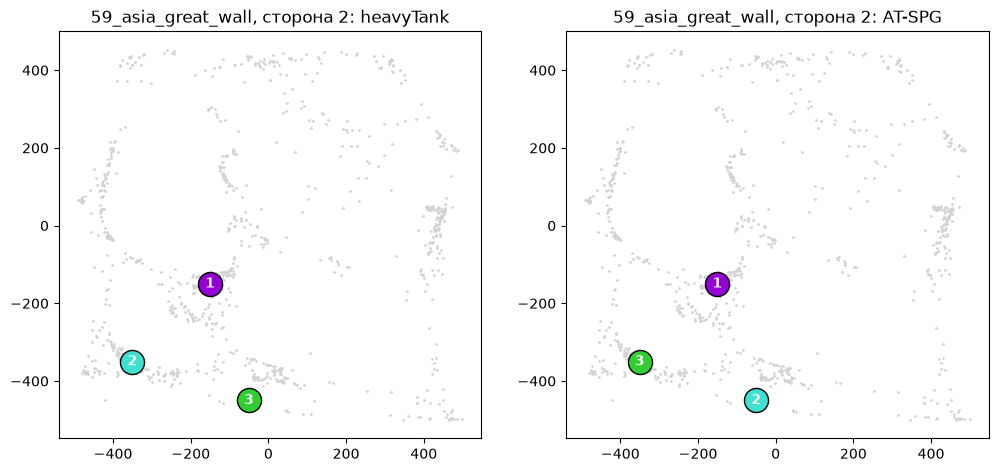

In [10]:
import matplotlib.pyplot as plt

MAP, TEAM = "59_asia_great_wall", 2
COLORS = {1: "darkviolet", 2: "turquoise", 3: "limegreen"}

full = advice(dev, BEST_TARGET, BEST_K_CLS)
side = full[(full["map_name"] == MAP) & (full["team"] == TEAM)].copy()
side["rank"] = side.groupby("tank_class")["score"].rank(ascending=False, method="first").astype(int)

points = dev[(dev["map_name"] == MAP)]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, cls in zip(axes, ["heavyTank", "AT-SPG"]):
    ax.scatter(points["x"], points["z"], s=1, c="lightgray")
    for row in side[side["tank_class"] == cls].itertuples():
        cx, cz = (row.zone_x + 0.5) * ZONE_SIZE, (row.zone_z + 0.5) * ZONE_SIZE
        ax.scatter(cx, cz, s=300, c=COLORS[row.rank], edgecolors="black")
        ax.text(cx, cz, str(row.rank), ha="center", va="center", color="white", weight="bold")
    ax.set_title(f"{MAP}, сторона {TEAM}: {cls}")
    ax.set_aspect("equal")
plt.show()